# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Google Colab на Tesla T4 с FAST_MODE = False. Основная модель - yolo26n.pt, Ultralytics 8.4.216. Датасет - Raccoon Detector Dataset(https://github.com/datitran/raccoon_dataset), 160 изображений в train и 40 в val. Репозиторий датасета помечен MIT, лицензии отдельных фотографий автор не перечисляет. Выполнены бонусы 6.2-6.5. При подготовке кода использовал документацию [YOLO26](https://docs.ultralytics.com/models/yolo26/)

In [1]:
%pip install -q -r requirements_cv.txt

In [2]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, subprocess, sys
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.4.0,<8.5'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.216, torch 2.14.1+cu130, device: Tesla T4


In [3]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [4]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [5]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
MODEL_INFO = {
    'ultralytics': ultralytics.__version__,
    'weights': weights_path.name,
    'sha256': hashlib.sha256(weights_path.read_bytes()).hexdigest(),
    'size_mb': weights_path.stat().st_size / 1_000_000,
    'params': sum(p.numel() for p in model_coco.model.parameters()),
    'n_classes_coco': len(model_coco.names),
}

benchmark_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
predict_args = dict(imgsz=IMGSZ, device=DEVICE, verbose=False)

for _ in range(5):
    model_coco.predict(benchmark_image, **predict_args)

if torch.cuda.is_available():
    torch.cuda.synchronize()

repeats = 20
start = time.perf_counter()
for _ in range(repeats):
    model_coco.predict(benchmark_image, **predict_args)

if torch.cuda.is_available():
    torch.cuda.synchronize()

MODEL_INFO['latency_ms'] = (time.perf_counter() - start) * 1000 / repeats

In [6]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 10.70440429999735}

**Ответ:** Для небольшого датасета с одним классом выбрал YOLO26n, чтобы сократить вычислительные затраты на T4. По таблице Ultralytics у YOLO26n и YOLO26s соответственно 2,4 и 9,5 млн параметров после оптимизации для инференса, 40,1 и 47,8 mAP50-95 на COCO в режиме end-to-end и 1,7 и 2,5 мс на T4 с TensorRT при входе 640 × 640.

Использовались Ultralytics 8.4.216 и yolo26n.pt размером 5,54 МБ. До первого predict модель содержала 2 572 280 параметров и поддерживала 80 классов. Среднее время вызова predict для кадра 640 × 640 на Tesla T4 составило 10,70 мс по 20 запускам после прогрева.

Код и предобученные веса доступны по AGPL-3.0. При распространении материалов под этой лицензией нужно сохранять уведомления о лицензии и предоставлять соответствующий исходный код. Пользователям, которые взаимодействуют с изменённой версией по сети, нужно дать возможность получить её исходный код

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [7]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    return {
      'backbone': sum(p.numel() for p in layers[:n_backbone].parameters()),
      'neck': sum(p.numel() for p in layers[n_backbone:-1].parameters()),
      'head': sum(p.numel() for p in layers[-1].parameters()),
  }


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feature_shapes = []

    def capture_inputs(_module, inputs):
        feature_shapes.extend(tuple(feature.shape) for feature in inputs[0])

    parameter = next(det_model.parameters())
    dummy = torch.zeros(
        (1, 3, imgsz, imgsz),
        dtype=parameter.dtype,
        device=parameter.device,
    )

    was_training = det_model.training
    hook = det_model.model[-1].register_forward_pre_hook(capture_inputs)
    try:
        det_model.eval()
        with torch.inference_mode():
            output = det_model(dummy)
    finally:
        hook.remove()
        det_model.train(was_training)

    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [8]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [9]:
print('Формы выходов модели:', shapes(out))

Формы выходов модели: [(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:** Backbone извлекает признаки и содержит 1 365 472 параметра (53,1 %), neck объединяет признаки разных масштабов и содержит 897 152 параметра (34,9 %), а на голову Detect приходится 309 656 параметров (12,0 %). При входе 640 × 640 голова получает карты 80 × 80, 40 × 40 и 20 × 20 с шагами 8, 16 и 32 и выдаёт по одному кандидату на позицию, всего 80² + 40² + 20² = 8400. У каждого кандидата четыре координаты рамки и 80 оценок классов, откуда форма выхода (1, 84, 8400). Детектор называют anchor-free, потому что рамку регрессируют относительно точки на карте признаков без заранее заданных размеров и пропорций шаблонных рамок.

При обучении ветка one2many сопоставляет одному объекту несколько позиций, поэтому при её использовании дубли убирает NMS. Ветка one2one учится сопоставлять каждому объекту одну позицию. При инференсе с nms=False YOLO26 использует эту ветку и отбирает детекции по уверенности без подавления по IoU.

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [10]:
from urllib.request import urlretrieve
from zipfile import ZipFile

CLASSES = ['raccoon']
class_to_id = {name: index for index, name in enumerate(CLASSES)}
DATASET_NAME = (
    'Raccoon Detector Dataset - https://github.com/datitran/raccoon_dataset'
    ' - MIT (лицензия репозитория)'
)

DATA_ROOT.mkdir(parents=True, exist_ok=True)
archive_path = DATA_ROOT / 'raccoon_dataset.zip'
dataset_dir = DATA_ROOT / 'raccoon_dataset-master'

if not archive_path.exists():
    partial_path = archive_path.with_suffix('.part')
    urlretrieve(
        'https://codeload.github.com/datitran/raccoon_dataset/zip/refs/heads/master',
        partial_path,
    )
    partial_path.replace(archive_path)

prefix = f'{dataset_dir.name}/'
split_files = {'train': 'train_labels.csv', 'val': 'test_labels.csv'}
csv_members = {f'{prefix}data/{name}' for name in split_files.values()}

with ZipFile(archive_path) as archive:
    members = [
        name for name in archive.namelist()
        if name in csv_members
        or name.startswith((f'{prefix}images/', f'{prefix}annotations/'))
    ]
    archive.extractall(DATA_ROOT, members)

names_by_split = {}
for split, csv_name in split_files.items():
    with (dataset_dir / 'data' / csv_name).open(encoding='utf-8', newline='') as file:
        names_by_split[split] = sorted({row['filename'] for row in csv.DictReader(file)})

assert set(names_by_split['train']).isdisjoint(names_by_split['val'])
assert set(names_by_split['train']) | set(names_by_split['val']) == {
    path.name for path in (dataset_dir / 'images').glob('*.jpg')
}

records = {}
cleaning = {}

for split, filenames in names_by_split.items():
    records[split] = []
    cleaning[split] = Counter()

    for filename in filenames:
        image_path = dataset_dir / 'images' / filename
        xml_path = dataset_dir / 'annotations' / f'{image_path.stem}.xml'
        annotation = ET.parse(xml_path).getroot()

        with Image.open(image_path) as image:
            width, height = image.size

        xml_size = (
            int(annotation.findtext('size/width')),
            int(annotation.findtext('size/height')),
        )
        if xml_size != (width, height):
            cleaning[split]['size_mismatch'] += 1

        bounds = np.array([width, height, width, height], dtype=np.float32)
        boxes, labels = [], []

        for obj in annotation.findall('object'):
            box = np.array([
                float(obj.findtext(f'bndbox/{key}'))
                for key in ('xmin', 'ymin', 'xmax', 'ymax')
            ], dtype=np.float32)

            if not np.isfinite(box).all():
                cleaning[split]['removed'] += 1
                continue

            clipped = np.clip(box, 0, bounds)
            if not np.array_equal(clipped, box):
                cleaning[split]['out_of_bounds'] += 1

            if (clipped[2:] <= clipped[:2]).any():
                cleaning[split]['removed'] += 1
                continue

            boxes.append(clipped)
            labels.append(class_to_id[obj.findtext('name').strip()])

        records[split].append(dict(
            image=image_path,
            width=width,
            height=height,
            boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
            labels=np.asarray(labels, dtype=np.int64),
        ))

for split, counts in cleaning.items():
    print(
        f'{split} | боксов за границей: {counts["out_of_bounds"]} | '
        f'удалено боксов: {counts["removed"]} | '
        f'несовпадений размеров XML и JPEG: {counts["size_mismatch"]}'
    )

train | боксов за границей: 0 | удалено боксов: 0 | несовпадений размеров XML и JPEG: 0
val | боксов за границей: 0 | удалено боксов: 0 | несовпадений размеров XML и JPEG: 0


In [11]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 160, 'val': 40}

train | изображений: 160 | объекты: {'raccoon': 173}
  объектов на кадр в среднем: 1.08 | пустых кадров: 0 | кадров с 2+ объектами: 12 | максимум: 3
  медиана площади бокса: 47.86% кадра | боксов меньше 1% кадра: 0
val | изображений: 40 | объекты: {'raccoon': 44}
  объектов на кадр в среднем: 1.10 | пустых кадров: 0 | кадров с 2+ объектами: 4 | максимум: 2
  медиана площади бокса: 51.77% кадра | боксов меньше 1% кадра: 0


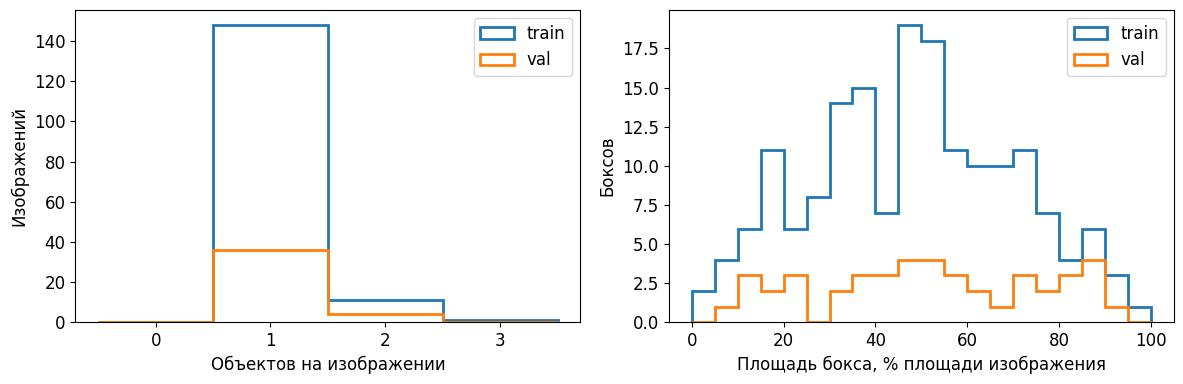

In [12]:
max_objects = max(len(r['labels']) for recs in records.values() for r in recs)
count_bins = np.arange(max_objects + 2) - 0.5
area_bins = np.linspace(0, 100, 21)

fig, (ax_count, ax_area) = plt.subplots(1, 2, figsize=(12, 4))

for split, recs in records.items():
    per_image = np.array([len(r['labels']) for r in recs])
    class_counts = np.bincount(
        np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES)
    )
    area_percent = np.concatenate([
        100 * np.prod(r['boxes'][:, 2:] - r['boxes'][:, :2], axis=1)
        / (r['width'] * r['height'])
        for r in recs
    ])

    print(f'{split} | изображений: {len(recs)} | объекты: {dict(zip(CLASSES, class_counts.tolist()))}')
    print(
        f'  объектов на кадр в среднем: {per_image.mean():.2f} | '
        f'пустых кадров: {(per_image == 0).sum()} | '
        f'кадров с 2+ объектами: {(per_image >= 2).sum()} | '
        f'максимум: {per_image.max()}'
    )
    if area_percent.size:
        print(
            f'  медиана площади бокса: {np.median(area_percent):.2f}% кадра | '
            f'боксов меньше 1% кадра: {(area_percent < 1).sum()}'
        )

    ax_count.hist(per_image, bins=count_bins, histtype='step', linewidth=2, label=split)
    ax_area.hist(area_percent, bins=area_bins, histtype='step', linewidth=2, label=split)

ax_count.set(xlabel='Объектов на изображении', ylabel='Изображений')
ax_count.set_xticks(range(max_objects + 1))
ax_area.set(xlabel='Площадь бокса, % площади изображения', ylabel='Боксов')
ax_count.legend()
ax_area.legend()
fig.tight_layout()
plt.show()

**Ответ:** Использовал Raccoon Detector Dataset Дата Трана с разметкой Pascal VOC XML. Сохранил авторское разбиение: 160 изображений и 173 объекта в train, 40 изображений и 44 объекта в val. В наборе один класс raccoon. Репозиторий помечен лицензией MIT, фотографии собраны из Google и Pixabay, отдельные лицензии снимков в репозитории не указаны.

В большинстве кадров по одному еноту. Кадров с двумя и более объектами всего 12 в train и 4 в val, максимум - три объекта на изображение. Медианная площадь рамки составляет 47,86 % кадра в train и 51,77 % в val, рамок площадью меньше 1 % кадра нет. Поэтому результаты будут в основном характеризовать детекцию крупных объектов в сценах с одним енотом. Проверка разметки не обнаружила боксов за пределами изображения, вырожденных рамок или расхождений размеров XML и JPEG.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [13]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels).reshape(-1)

    if len(boxes) != len(labels):
        raise ValueError('Число боксов и меток должно совпадать')

    top_left = boxes[:, :2]
    bottom_right = boxes[:, 2:]
    centers = (top_left + bottom_right) / 2
    sizes = bottom_right - top_left
    normalized = np.concatenate([centers, sizes], axis=1)
    normalized /= [width, height, width, height]

    return '\n'.join(
        f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}'
        for label, (cx, cy, w, h) in zip(labels, normalized)
    )


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    box_rows = []
    labels = []

    for line in text.splitlines():
        if not line.strip():
            continue
        label, cx, cy, w, h = line.split()
        labels.append(int(label))
        box_rows.append([float(cx), float(cy), float(w), float(h)])

    normalized = np.asarray(box_rows, dtype=np.float64).reshape(-1, 4)
    centers = normalized[:, :2]
    half_sizes = normalized[:, 2:] / 2
    boxes = np.concatenate([centers - half_sizes, centers + half_sizes], axis=1)
    boxes *= [width, height, width, height]

    return boxes.astype(np.float32), np.asarray(labels, dtype=np.int64)

In [14]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [15]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    images_dir = YOLO_ROOT / 'images' / split
    labels_dir = YOLO_ROOT / 'labels' / split
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    for record in recs:
        source = Path(record['image'])
        shutil.copy2(source, images_dir / source.name)

        label_text = to_yolo(
            record['boxes'], record['labels'], record['width'], record['height']
        )
        (labels_dir / f'{source.stem}.txt').write_text(label_text, encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: /content/data/yolo
train: images/train
val: images/val
names:
  0: raccoon



Проверено txt-файлов: 200
Максимальное отклонение координаты: 0.000549 px


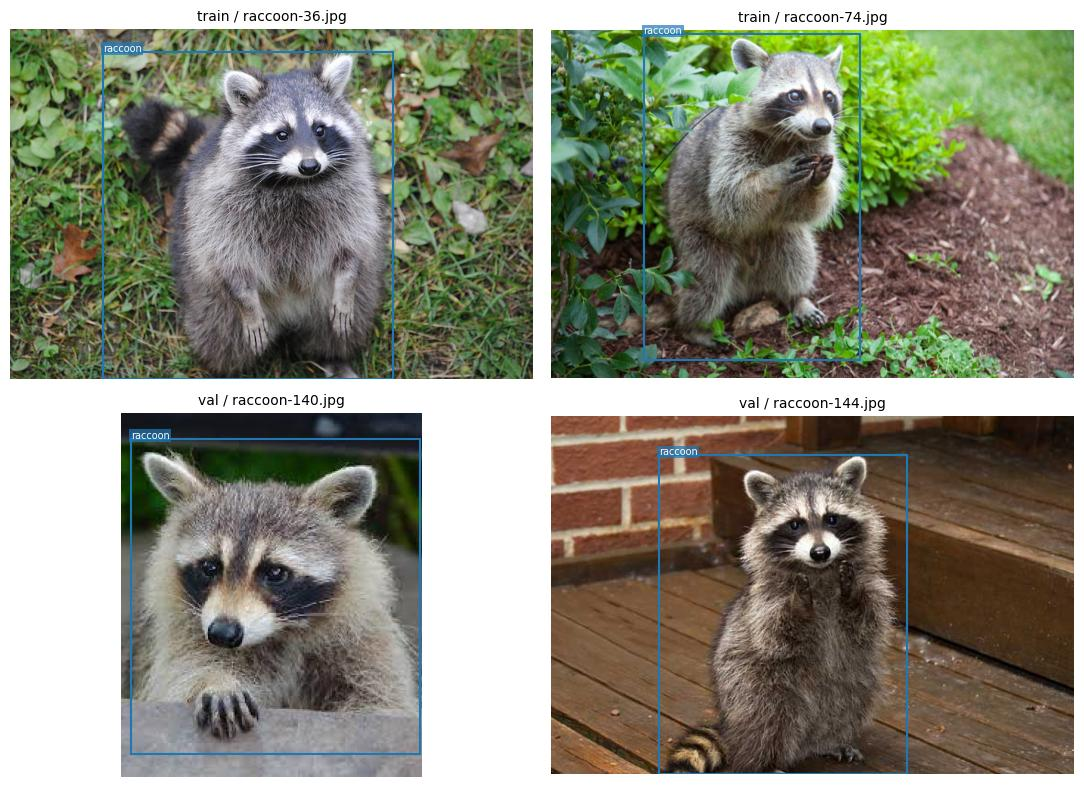

In [16]:
rng = np.random.default_rng(SEED)
examples = []
checked = 0
max_error_px = 0.0

for split, recs in splits.items():
    selected = set(rng.choice(len(recs), size=2, replace=False))

    for index, record in enumerate(recs):
        filename = Path(record['image']).name
        label_path = YOLO_ROOT / 'labels' / split / f'{Path(filename).stem}.txt'
        width, height = record['width'], record['height']

        boxes_back, labels_back = from_yolo(
            label_path.read_text(encoding='utf-8'), width, height
        )
        np.testing.assert_array_equal(labels_back, record['labels'])
        np.testing.assert_allclose(
            boxes_back, record['boxes'], rtol=0, atol=1e-6 * max(width, height)
        )

        error_px = np.max(np.abs(boxes_back - record['boxes']), initial=0.0)
        max_error_px = max(max_error_px, float(error_px))
        checked += 1

        if index in selected:
            copied_image = YOLO_ROOT / 'images' / split / filename
            examples.append((split, copied_image, boxes_back, labels_back))

print(f'Проверено txt-файлов: {checked}')
print(f'Максимальное отклонение координаты: {max_error_px:.6f} px')

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (split, path, boxes, labels) in zip(axes.flat, examples):
    with Image.open(path) as image:
        draw_boxes(ax, image.convert('RGB'), boxes, labels, CLASSES,
                   title=f'{split} / {path.name}')
fig.tight_layout()
plt.show()

**Ответ:** Проверил обратное преобразование для всех 200 экспортированных TXT-файлов. Метки классов сохранились, максимальное отклонение координаты составило 0,000549 пикселя при записи нормированных значений с шестью знаками после запятой. На четырёх примерах из train и val восстановленные рамки соответствуют положению енотов.

Проверка туда-обратно подтверждает сохранение исходных координат и меток. Согласованная ошибка в обеих функциях может пройти такую проверку, поэтому в шаблоне также есть тесты с заранее известными значениями. Отрисовка помогает заметить сдвиг или растяжение рамки относительно объекта и ошибки при сопоставлении рамок с изображениями

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

Сплит: val | изображений: 40
Изображений с детекциями при conf >= 0.25: 38
Предсказанные классы COCO: {'cat': 23, 'bear': 16, 'person': 7, 'dog': 7, 'bowl': 4, 'tie': 2, 'chair': 2, 'bird': 1, 'bed': 1, 'dining table': 1, 'laptop': 1}
mAP50 COCO по классу raccoon: 0.0


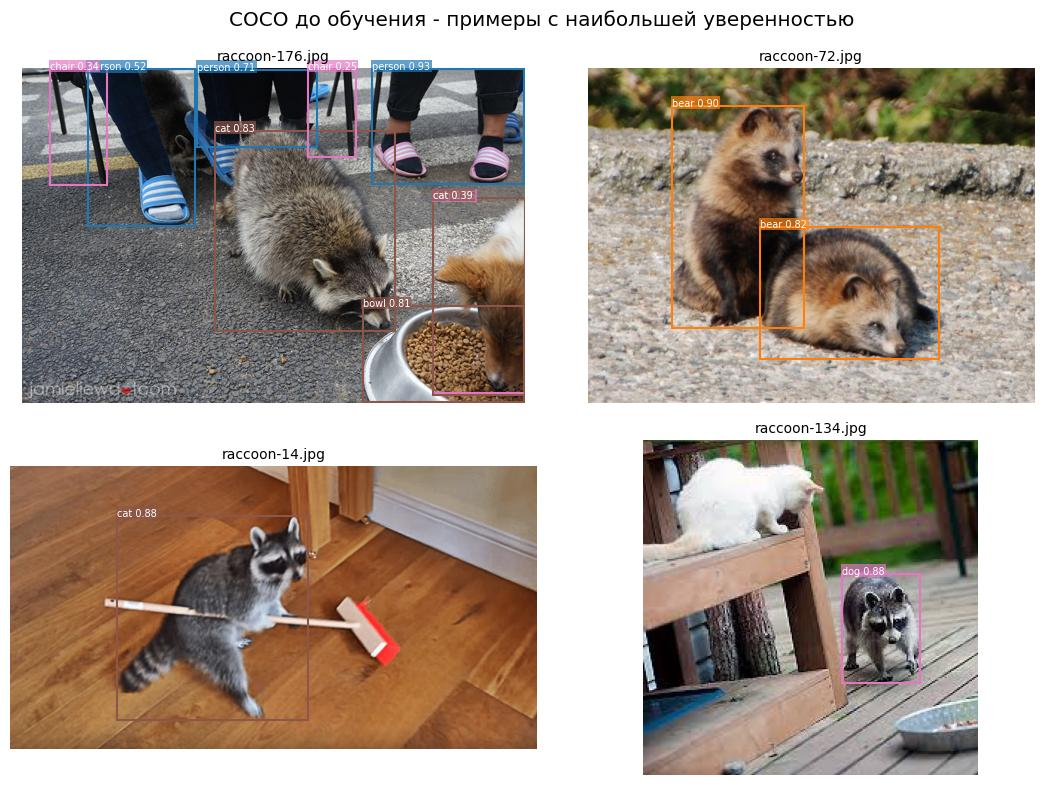

In [17]:
baseline_recs = records[FINAL_SPLIT]
coco_names = model_coco.names
assert set(CLASSES).isdisjoint(coco_names.values())

coco_map50 = 0.0
coco_conf = 0.25
coco_preds = predict_records(model_coco, baseline_recs, conf=coco_conf)

coco_counts = Counter(
    coco_names[int(label)]
    for pred in coco_preds
    for label in pred['labels']
)
n_with_predictions = sum(len(pred['labels']) > 0 for pred in coco_preds)

print(f'Сплит: {FINAL_SPLIT} | изображений: {len(baseline_recs)}')
print(f'Изображений с детекциями при conf >= {coco_conf}: {n_with_predictions}')
print('Предсказанные классы COCO:', dict(coco_counts.most_common()))
print('mAP50 COCO по классу raccoon:', coco_map50)

example_indices = sorted(
    range(len(baseline_recs)),
    key=lambda index: float(coco_preds[index]['scores'].max(initial=0.0)),
    reverse=True,
)[:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, index in zip(axes.flat, example_indices):
    record = baseline_recs[index]
    pred = coco_preds[index]
    with Image.open(record['image']) as image:
        draw_boxes(
            ax, image.convert('RGB'), pred['boxes'], pred['labels'], coco_names,
            scores=pred['scores'], title=Path(record['image']).name,
        )

fig.suptitle('COCO до обучения - примеры с наибольшей уверенностью')
fig.tight_layout()
plt.show()

In [18]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    with Image.open(image_path) as image:
      width, height = image.size

    scale = np.array([width, height, width, height], dtype=np.float32)
    box = heuristic_box_norm * scale

    return {
        'boxes': box.reshape(1, 4),
        'scores': np.ones(1, dtype=np.float32),
        'labels': np.zeros(1, dtype=np.int64),
    }

In [19]:
train_boxes_norm = np.concatenate([
    record['boxes'] / np.array(
        [record['width'], record['height'], record['width'], record['height']],
        dtype=np.float32,
    )
    for record in train_recs
])

heuristic_box_norm = np.median(train_boxes_norm, axis=0).astype(np.float32)

print(f'Шаблон рассчитан по {len(train_boxes_norm)} боксам из train')
print('Медианные координаты xyxy в долях кадра:', np.round(heuristic_box_norm, 3))

Шаблон рассчитан по 173 боксам из train
Медианные координаты xyxy в долях кадра: [      0.156       0.089       0.796       0.924]


Изображений с IoU >= 0.5: 31/40
Медианный IoU с ближайшей рамкой разметки: 0.638


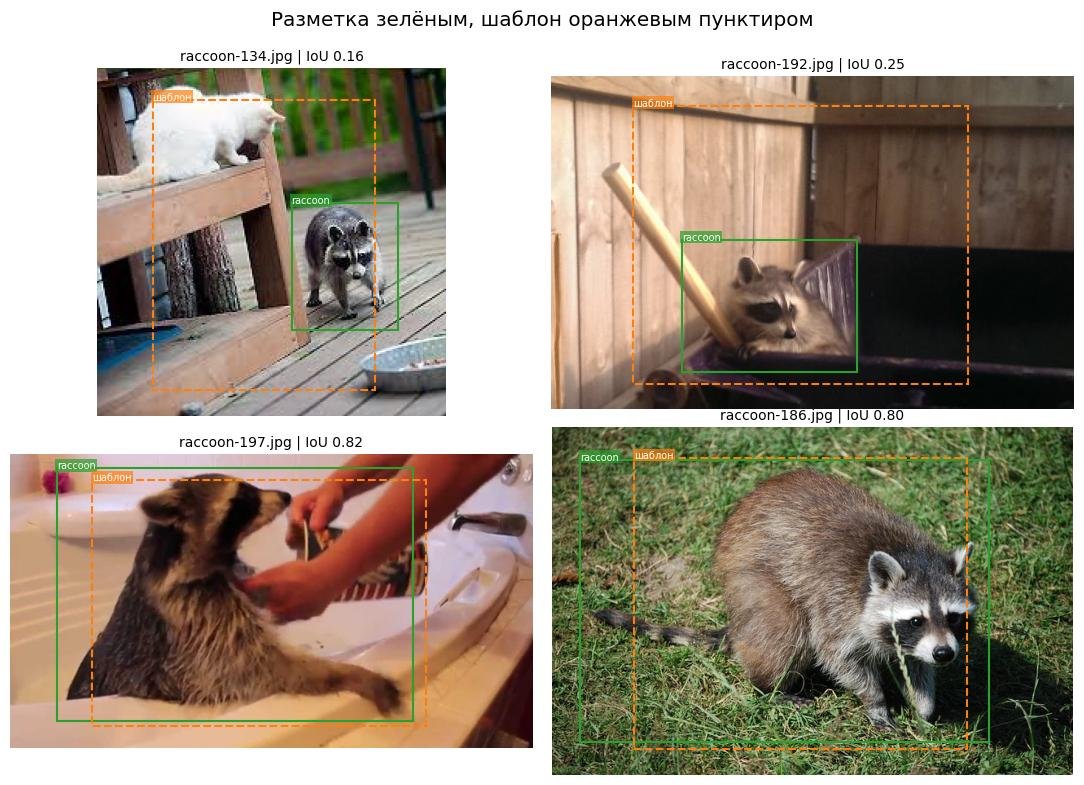

{'split': 'val',
 'coco_map50': 0.0,
 'heuristic_map50': 0.5891608391608392,
 'heuristic_ap50_per_class': {'raccoon': 0.5891608391608392}}

In [20]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
best_ious = []
for pred, record in zip(heuristic_preds, baseline_recs):
    overlaps = box_iou(
        torch.as_tensor(pred['boxes']),
        torch.as_tensor(record['boxes']),
    )
    best_ious.append(overlaps.max().item() if overlaps.numel() else 0.0)

n_hits = np.count_nonzero(np.asarray(best_ious) >= 0.5)
print(f'Изображений с IoU >= 0.5: {n_hits}/{len(baseline_recs)}')
print(f'Медианный IoU с ближайшей рамкой разметки: {np.median(best_ious):.3f}')

order = np.argsort(best_ious, kind='stable')
example_indices = [*order[:2], *order[-2:][::-1]]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, index in zip(axes.flat, example_indices):
    record = baseline_recs[index]
    pred = heuristic_preds[index]
    title = f'{Path(record["image"]).name} | IoU {best_ious[index]:.2f}'

    with Image.open(record['image']) as image:
        draw_boxes(
            ax, image.convert('RGB'), record['boxes'], record['labels'],
            CLASSES, color='tab:green', title=title,
        )

    draw_boxes(
        ax, None, pred['boxes'], pred['labels'], ['шаблон'],
        color='tab:orange', linestyle='--',
    )

fig.suptitle('Разметка зелёным, шаблон оранжевым пунктиром')
fig.tight_layout()
plt.show()
BASELINE

**Ответ:** Предобученная COCO-модель выдала детекции на 38 из 40 кадров при conf ≥ 0,25. Чаще всего встречались метки cat (23 бокса) и bear (16). Например, на raccoon-72.jpg модель выделила обоих енотов, присвоив им класс bear с уверенностью 0,90 и 0,82. Класса raccoon в COCO нет, поэтому mAP50 по нему равен 0.

Шаблон по 173 тренировочным рамкам дал mAP50 = 0,5892. Он достиг IoU ≥ 0,5 на 31 из 40 кадров, медианный IoU составил 0,638. На raccoon-197.jpg крупный объект хорошо совпал с шаблоном (IoU 0,82), а на raccoon-134.jpg енот был меньше и смещён вправо (IoU 0,16). Шаблон выдаёт одну рамку фиксированного относительного размера и положения, поэтому его качество зависит от композиции кадра

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [21]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [22]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    nbs=BATCH,
    optimizer='AdamW',
    lr0=1e-3,
    lrf=0.10,
    momentum=0.9,
    weight_decay=5e-4,
    warmup_epochs=0.0 if FAST_MODE else 2.0,
    warmup_bias_lr=0.0,
    patience=12,
    degrees=8.0,
    translate=0.10,
    scale=0.20,
    fliplr=0.50,
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.40,
    hsv_v=0.30,
    mosaic=0.0,
    mixup=0.0,
    val=True,
    amp=torch.cuda.is_available(),
    seed=SEED,
    deterministic=True,
    plots=False,
)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.9, mosaic=0.0, multi_scale=0.0, name=finetune, nbs=16, nms=None, opset=None, optimize=False, optimizer=AdamW

train/box_loss: 1.8753 → 0.5970
val/box_loss: 1.4161 → 1.4194
train/cls_loss: 24.3888 → 0.2117
val/cls_loss: 18.9502 → 0.6821
train/l1_loss: 0.0613 → 0.0180
val/l1_loss: 0.0434 → 0.0472
val mAP50: 0.1923 → 0.9594
Максимум val mAP50: 0.9696 на эпохе 38


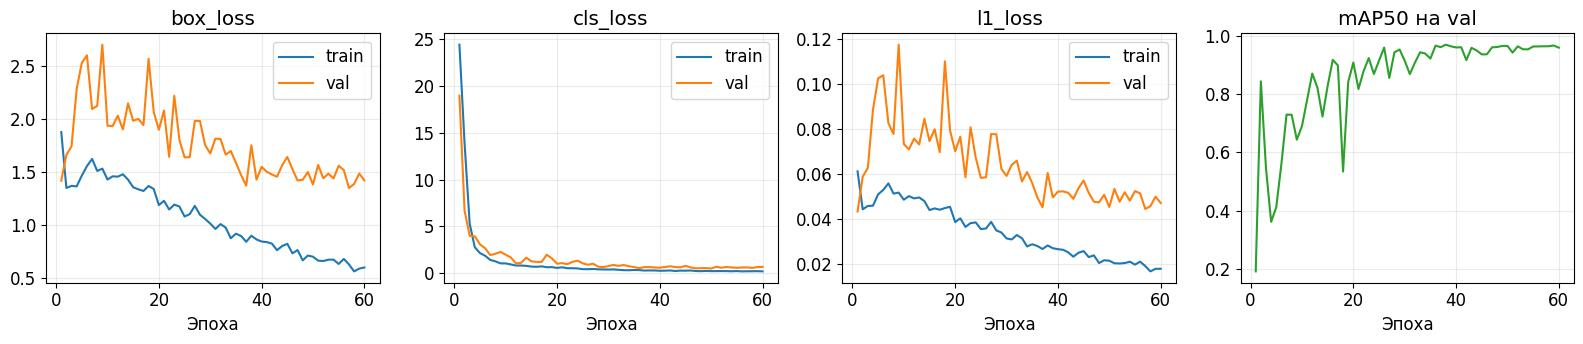

In [23]:
history = read_results(run_dir)
epochs = history['epoch'].astype(int)

loss_names = list(dict.fromkeys(
    key.split('/', 1)[1]
    for key in history
    if key.startswith(('train/', 'val/')) and key.endswith('_loss')
))
map50_key = next(
    key for key in history if key.split('(', 1)[0] == 'metrics/mAP50'
)

n_plots = len(loss_names) + 1
fig, axes = plt.subplots(
    1, n_plots, figsize=(4 * n_plots, 3.6), squeeze=False
)
axes = axes[0]
marker = 'o' if len(epochs) <= 10 else None

for ax, loss_name in zip(axes, loss_names):
    for split in ('train', 'val'):
        key = f'{split}/{loss_name}'
        if key in history:
            values = history[key]
            ax.plot(epochs, values, marker=marker, label=split)
            print(f'{key}: {values[0]:.4f} → {values[-1]:.4f}')
    ax.set_title(loss_name)
    ax.legend()

map50 = history[map50_key]
axes[-1].plot(epochs, map50, color='tab:green', marker=marker)
axes[-1].set_title('mAP50 на val')

for ax in axes:
    ax.set_xlabel('Эпоха')
    if len(epochs) <= 10:
        ax.set_xticks(epochs)
    ax.grid(alpha=0.25)

best_index = int(np.argmax(map50))
print(f'val mAP50: {map50[0]:.4f} → {map50[-1]:.4f}')
print(f'Максимум val mAP50: {map50[best_index]:.4f} на эпохе {epochs[best_index]}')

fig.tight_layout()
plt.show()

**Ответ:** YOLO26n дообучалась на 160 изображениях в течение 60 эпох. Прогон занял 212,7 с на Tesla T4. Вход 640 × 640 выбрал для более точной локализации границ, а batch=16 уложился в память GPU. Использовал AdamW с начальным lr=0,001, двухэпоховый прогрев и patience=12. Небольшие повороты, сдвиги, масштабирование, горизонтальные отражения и изменения цвета разнообразили тренировочные кадры при сохранении естественной ориентации животных.

train/box_loss снизился с 1,8753 до 0,5970, а валидационные потери локализации к концу колебались без устойчивого роста. Разрыв между train и val заметен, но выраженного ухудшения качества на val в конце прогона не видно. mAP50 выросла с 0,1923 до 0,9594, достигнув максимума 0,9696 на эпохе 38. Шестидесяти эпох хватило, чтобы выйти на плато по mAP50

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [24]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2475.5±1503.9 MB/s, size: 78.9 KB)
val: Scanning /content/data/yolo/labels/val.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 9.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.8it/s 1.1s
                   all         40         44      0.975      0.882      0.961      0.588
Speed: 3.8ms preprocess, 4.6ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/runs_hw2/eval_val
val | общие метрики {'precision': 0.9749, 'recall': 0.8818, 'map50': 0.9607, 'map50_95': 0.5881}
val | raccoon {'precision': 0.9749, 'recall': 0.8818, 'map50': 0.9607, 'map50_95': 0.5881}
val | матрица ошибок, строки - прогноз, столбцы - разметка
[[43 58]
 [ 1  0]]


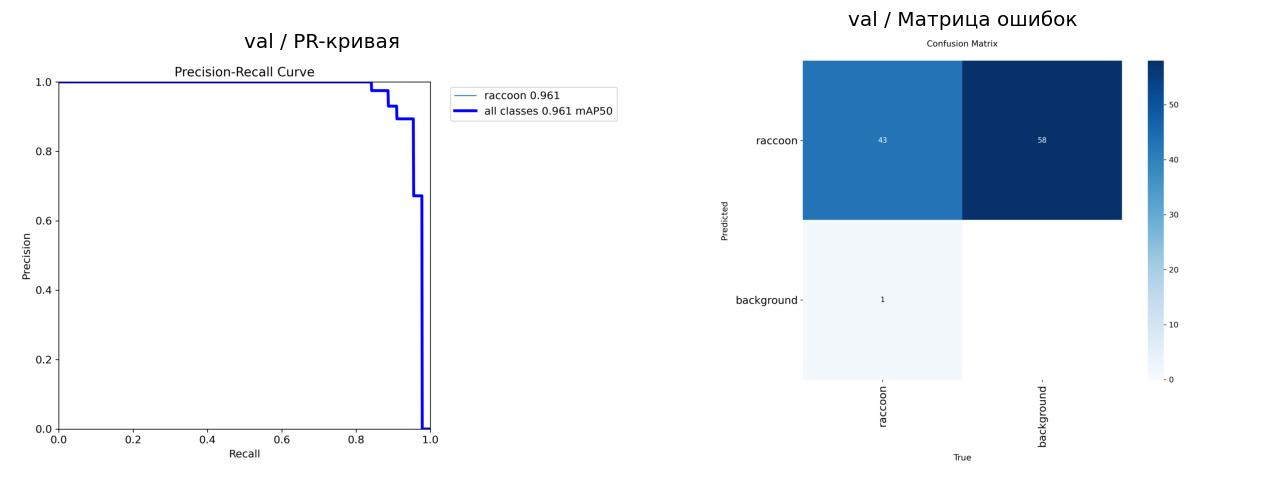

mAP50 Ultralytics: 0.9607
mAP50 evaluate_map50: 0.9628
Абсолютная разница: 0.0020


In [25]:
EVAL_ARGS = dict(conf=0.001, iou=0.7, max_det=300, rect=False)
metric_keys = ('precision', 'recall', 'map50', 'map50_95')
metrics_by_split = {}

for split in ('val', 'test'):
    if split not in records:
        continue

    result = val_metrics(best, split, f'eval_{split}', plots=True, **EVAL_ARGS)
    overall = dict(zip(metric_keys, map(float, result.mean_results())))
    per_class = {
        CLASSES[int(class_id)]: dict(
            zip(metric_keys, map(float, result.class_result(index)))
        )
        for index, class_id in enumerate(result.ap_class_index)
    }
    metrics_by_split[split] = dict(overall, per_class=per_class)

    print(f'{split} | общие метрики', {k: round(v, 4) for k, v in overall.items()})
    for class_name, values in per_class.items():
        print(f'{split} | {class_name}', {k: round(v, 4) for k, v in values.items()})

    print(f'{split} | матрица ошибок, строки - прогноз, столбцы - разметка')
    print(result.confusion_matrix.matrix.astype(int))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, filename, title in zip(
        axes,
        ('BoxPR_curve.png', 'confusion_matrix.png'),
        ('PR-кривая', 'Матрица ошибок'),
    ):
        ax.imshow(plt.imread(Path(result.save_dir) / filename))
        ax.set_title(f'{split} / {title}')
        ax.axis('off')
    fig.tight_layout()
    plt.show()

final_recs = records[FINAL_SPLIT]
final_preds = predict_records(best, final_recs, batch=BATCH, **EVAL_ARGS)
manual_map50, _ = evaluate_map50(final_preds, final_recs, len(CLASSES))

FINAL = dict(
    metrics_by_split[FINAL_SPLIT],
    split=FINAL_SPLIT,
    map50_manual=float(manual_map50),
)

print(f'mAP50 Ultralytics: {FINAL["map50"]:.4f}')
print(f'mAP50 evaluate_map50: {FINAL["map50_manual"]:.4f}')
print(f'Абсолютная разница: {abs(FINAL["map50"] - FINAL["map50_manual"]):.4f}')

In [26]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'precision': 0.9749,
 'recall': 0.8818,
 'map50': 0.9607,
 'map50_95': 0.5881,
 'split': 'val',
 'map50_manual': 0.9628}

**Ответ:** На val из 40 изображений и 44 объектов best.pt дал precision 0,9749, recall 0,8818, mAP50 0,9607 и mAP50–95 0,5881. В наборе один класс raccoon, поэтому его метрики совпадают с общими. Снижение AP при более строгих порогах IoU показывает, что точное совпадение границ рамок остаётся сложнее обнаружения самого объекта.

При conf=0,001 матрица показывает 43 совпадения, 58 лишних рамок в столбце background и один пропущенный объект в строке background. Сводные precision и recall соответствуют рабочей точке, выбранной по F1, поэтому отличаются от значений при пороге матрицы.

evaluate_map50 дал 0,9628. Абсолютная разница с Ultralytics составила 0,0020 до округления. На неё могут влиять правила сопоставления рамок, обработка изображений при predict и val и способ интегрирования PR-кривой

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [27]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)

    top_left = np.maximum(a[:, None, :2], b[None, :, :2])
    bottom_right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(bottom_right - top_left, 0).prod(axis=2)

    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection

    return np.divide(
        intersection, union, out=np.zeros_like(intersection), where=union > 0
    )


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    pred_labels = np.asarray(pred['labels']).reshape(-1)
    gt_labels = np.asarray(gt['labels']).reshape(-1)
    scores = np.asarray(pred['scores'], dtype=np.float64).reshape(-1)
    overlaps = box_iou_np(pred['boxes'], gt['boxes'])

    categories = ['background'] * len(pred_labels)
    matched = np.zeros(len(gt_labels), dtype=bool)
    explained = np.zeros(len(gt_labels), dtype=bool)

    for index in np.argsort(-scores, kind='stable'):
        ious = overlaps[index]
        same_class = gt_labels == pred_labels[index]
        hit = ious >= iou_hit

        candidates = (
            ('tp', same_class & hit & ~matched),
            ('class', ~same_class & hit),
            ('localization', same_class & ~matched & (ious >= iou_loc) & ~hit),
        )

        for category, mask in candidates:
            indices = np.flatnonzero(mask)
            if not indices.size:
                continue

            gt_index = indices[np.argmax(ious[indices])]
            categories[index] = category
            explained[gt_index] = True
            if category == 'tp':
                matched[gt_index] = True
            break

    return categories, np.flatnonzero(~explained).tolist()

In [28]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


conf >= 0.25 | предсказаний: 43 | объектов в разметке: 44
tp: 40 (93.0%) | по классам: {'raccoon': 40}
class: 0 (0.0%) | по классам: {}
localization: 2 (4.7%) | по классам: {'raccoon': 2}
background: 1 (2.3%) | по классам: {'raccoon': 1}
missed: 2 (4.5%) | по классам: {'raccoon': 2}


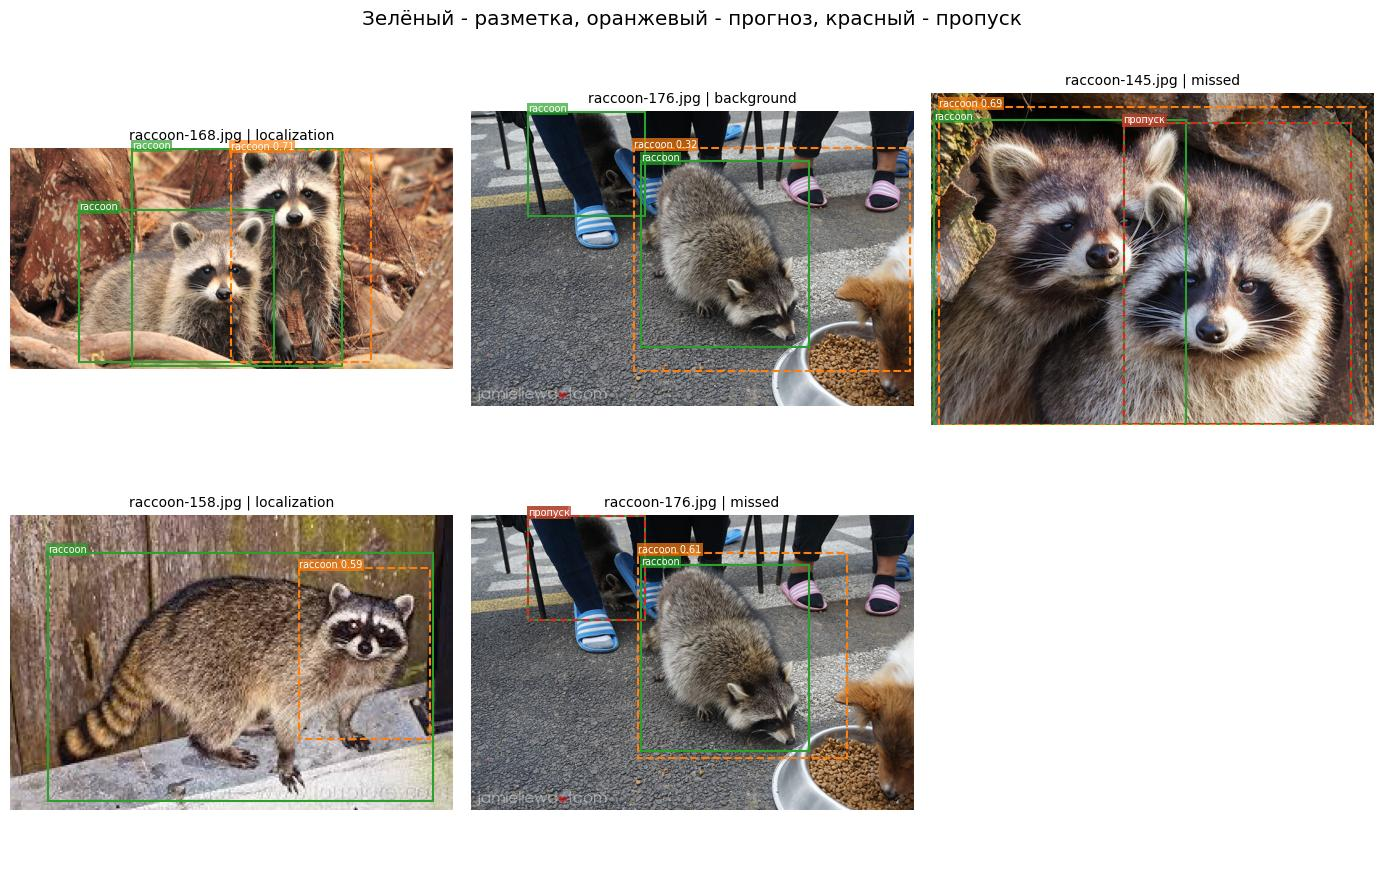

In [29]:
error_recs = records['val']
error_preds = predict_records(
    best, error_recs, batch=BATCH, **dict(EVAL_ARGS, conf=CONF_ERRORS)
)

ERRORS = dict.fromkeys(ERROR_TYPES, 0)
counts_by_class = {category: Counter() for category in ERROR_TYPES}
examples_by_type = {category: [] for category in ERROR_TYPES if category != 'tp'}

for record, raw_pred in zip(error_recs, error_preds):
    keep = raw_pred['scores'] >= CONF_ERRORS
    pred = {key: values[keep] for key, values in raw_pred.items()}

    categories, missed = categorize_predictions(pred, record)
    categories = np.asarray(categories, dtype=str)

    for category in ERROR_TYPES[:-1]:
        indices = np.flatnonzero(categories == category)
        ERRORS[category] += len(indices)
        counts_by_class[category].update(
            CLASSES[int(label)] for label in pred['labels'][indices]
        )

        if category != 'tp' and indices.size:
            index = indices[np.argmax(pred['scores'][indices])]
            score = float(pred['scores'][index])
            examples_by_type[category].append((score, record, pred, index))

    ERRORS['missed'] += len(missed)
    counts_by_class['missed'].update(
        CLASSES[int(record['labels'][index])] for index in missed
    )
    if missed:
        examples_by_type['missed'].append((0.0, record, pred, missed[0]))

n_preds = sum(ERRORS[category] for category in ERROR_TYPES[:-1])
n_gt = sum(len(record['labels']) for record in error_recs)
print(f'conf >= {CONF_ERRORS} | предсказаний: {n_preds} | объектов в разметке: {n_gt}')

for category, count in ERRORS.items():
    total = n_gt if category == 'missed' else n_preds
    share = count / total if total else 0.0
    print(f'{category}: {count} ({share:.1%}) | по классам: {dict(counts_by_class[category])}')

ranked_examples = []
for category, candidates in examples_by_type.items():
    candidates.sort(key=lambda item: item[0], reverse=True)
    ranked_examples.extend(
        (rank, category, example) for rank, example in enumerate(candidates)
    )
examples = sorted(ranked_examples, key=lambda item: item[0])[:6]

if examples:
    rows = (len(examples) + 2) // 3
    fig, axes = plt.subplots(rows, 3, figsize=(14, 4.5 * rows), squeeze=False)

    for ax in axes.flat:
        ax.axis('off')

    for ax, (_, category, (_, record, pred, index)) in zip(axes.flat, examples):
        title = f'{Path(record["image"]).name} | {category}'
        with Image.open(record['image']) as image:
            draw_boxes(
                ax, image.convert('RGB'), record['boxes'], record['labels'],
                CLASSES, color='tab:green', title=title,
            )

        if category == 'missed':
            draw_boxes(
                ax, None, record['boxes'][[index]], record['labels'][[index]],
                ['пропуск'], color='tab:red', linestyle='--',
            )
            shown = np.argsort(-pred['scores'], kind='stable')[:1]
        else:
            shown = [index]

        draw_boxes(
            ax, None, pred['boxes'][shown], pred['labels'][shown],
            CLASSES, scores=pred['scores'][shown], color='tab:orange',
            linestyle='--',
        )

    fig.suptitle('Зелёный - разметка, оранжевый - прогноз, красный - пропуск')
    fig.tight_layout()
    plt.show()

**Ответ:** При conf ≥ 0,25 из 43 прогнозов 40 совпали с разметкой, два отнесены к ошибкам локализации и один к background. Отдельно учтены два пропуска из 44 размеченных объектов. Локализация и пропуски встречались одинаково часто. На raccoon-158.jpg прогноз обвёл голову вместо всего тела. На raccoon-145.jpg одна широкая рамка захватила двух енотов, и для правого не нашлось отдельной подходящей рамки. На raccoon-176.jpg модель пропустила частично закрытого енота рядом с ногами людей.

В этих примерах у соответствующих объектов есть рамки разметки. Чтобы уменьшить число таких ошибок, я бы добавил больше тренировочных кадров с несколькими енотами, перекрытиями и плохим освещением, а также проверил полноту разметки подобных сцен

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [30]:
n_frozen = len(arch.yaml['backbone'])
ablation_args = dict(TRAIN_ARGS, freeze=n_frozen)

model_frozen, RUN_TIMES['ablation'], ablation_dir = train_yolo(
    'ablation_freeze', weights=WEIGHTS, **ablation_args
)
best_frozen = YOLO(ablation_dir / 'weights' / 'best.pt')
frozen_val = val_metrics(
    best_frozen, 'val', 'eval_ablation_freeze', plots=False, **EVAL_ARGS
)

base_val = metrics_by_split['val']
ABLATION = {
    'parameter': 'freeze',
    'baseline': {
        'value': 0,
        'map50': base_val['map50'],
        'map50_95': base_val['map50_95'],
        'train_time_sec': RUN_TIMES['train'],
        'epochs_completed': len(read_results(run_dir)['epoch']),
    },
    'frozen': {
        'value': n_frozen,
        'map50': float(frozen_val.box.map50),
        'map50_95': float(frozen_val.box.map),
        'train_time_sec': RUN_TIMES['ablation'],
        'epochs_completed': len(read_results(ablation_dir)['epoch']),
    },
}

for variant in ('baseline', 'frozen'):
    row = ABLATION[variant]
    print(
        f'freeze={row["value"]} | эпох: {row["epochs_completed"]} | '
        f'mAP50={row["map50"]:.4f} | mAP50–95={row["map50_95"]:.4f} | '
        f'время={row["train_time_sec"]:.1f} с'
    )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.9, mosaic=0.0, multi_scale=0.0, name=ablation_freeze, nbs=16, nms=None, opset=None, optimize=False, optimizer=

**Ответ:** При заморозке 11 слоёв backbone mAP50 снизилась с 0,9607 до 0,9126, а mAP50-95 - с 0,5881 до 0,5747. Обучение сократилось с 212,7 до 143,7 с. Часть экономии связана с ранней остановкой на 48-й эпохе, тогда как основной вариант прошёл 60 эпох. Заморозка могла ограничить адаптацию признаков к датасету. Для этого эксперимента я бы оставил полное дообучение, поскольку оно дало более высокое качество по обеим метрикам

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** После дообучения YOLO26n mAP50 выросла с 0,5892 у шаблона до 0,9628 при оценке одной и той же функцией evaluate_map50. У исходной COCO-модели mAP50 по енотам равна 0 из-за отсутствия класса raccoon. По Ultralytics итоговая модель получила mAP50 0,9607 и mAP50–95 0,5881, поэтому запас для улучшения остаётся прежде всего в точности рамок. При рабочем пороге 0,25 обнаружены две ошибки локализации, одна лишняя рамка и два пропуска. Заморозка backbone сэкономила около 69 с, но снизила mAP50 на 0,0481. Эксперимент ограничен одним seed, 40 валидационными кадрами, возможной неполнотой разметки и использованием val для выбора чекпойнта и оценки. Дальше я бы проверил модель на отдельном тестовом наборе с перекрытыми объектами, шумом и сложным освещением.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [31]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


In [32]:
bonus_checkpoint = run_dir / 'weights' / 'best.pt'
bonus_val = records['val']

with Image.open(bonus_val[0]['image']) as image:
    bench_image = np.asarray(image.convert('RGB'))[:, :, ::-1].copy()

bench_args = dict(EVAL_ARGS, conf=0.25)


def benchmark_predict_ms(model, device, warmup=5, repeats=20):
    kwargs = dict(bench_args, imgsz=IMGSZ, device=device, verbose=False)

    for _ in range(warmup):
        model.predict(bench_image, **kwargs)

    actual_device = model.predictor.device
    if actual_device.type == 'cuda':
        torch.cuda.synchronize(actual_device)

    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(bench_image, **kwargs)
        if actual_device.type == 'cuda':
            torch.cuda.synchronize(actual_device)

    return 1000 * (time.perf_counter() - start) / repeats

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [33]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [34]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR

    saved_metrics = json.loads(
        (artifact_dir / 'metrics.json').read_text(encoding='utf-8')
    )
    yolo_val = metrics_by_split['val']

    rt_batch = 2
    rt_args = dict(
        TRAIN_ARGS,
        batch=rt_batch,
        nbs=rt_batch,
        lr0=1e-4,
        amp=False,
        deterministic=False,
    )

    rt_model = RTDETR('rtdetr-l.pt')
    start = time.perf_counter()
    rt_model.train(
        data=str(DATA_YAML), device=DEVICE, workers=WORKERS,
        project=str(RUNS.resolve()), name='rtdetr_l',
        exist_ok=True, verbose=False, **rt_args,
    )
    rt_train_sec = time.perf_counter() - start
    rt_dir = Path(rt_model.trainer.save_dir)
    del rt_model

    yolo_model = YOLO(bonus_checkpoint)
    rt_best = RTDETR(rt_dir / 'weights' / 'best.pt')
    yolo_params = sum(p.numel() for p in yolo_model.model.parameters())
    rt_params = sum(p.numel() for p in rt_best.model.parameters())

    rt_val = rt_best.val(
        data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=rt_batch,
        device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
        name='eval_rtdetr_l', exist_ok=True, verbose=False,
        plots=False, **EVAL_ARGS,
    )

    RTDETR_COMPARE = {
        'YOLO26n': dict(
            epochs=len(read_results(run_dir)['epoch']),
            params=yolo_params,
            map50=yolo_val['map50'],
            map50_95=yolo_val['map50_95'],
            train_sec=float(saved_metrics['train_time_sec']),
            latency_ms=benchmark_predict_ms(yolo_model, DEVICE),
        ),
        'RT-DETR-L': dict(
            epochs=len(read_results(rt_dir)['epoch']),
            params=rt_params,
            map50=float(rt_val.box.map50),
            map50_95=float(rt_val.box.map),
            train_sec=rt_train_sec,
            latency_ms=benchmark_predict_ms(rt_best, DEVICE),
        ),
    }

    print(f'Устройство: {DEVICE_NAME} | imgsz={IMGSZ} | замер при batch=1')
    for name, row in RTDETR_COMPARE.items():
        print(
            f'{name} | эпох: {row["epochs"]} | параметров: {row["params"]:,} | '
            f'mAP50={row["map50"]:.4f} | mAP50–95={row["map50_95"]:.4f} | '
            f'обучение={row["train_sec"]:.1f} с | кадр={row["latency_ms"]:.2f} мс'
        )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=8.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.9, mosaic=0.0, multi_scale=0.0, name=rtdetr_l, nbs=2, nms=None, opset=None, optimize=False, optimizer=Ada

**Ответ:** На том же val RT-DETR-L дал mAP50 0,9504 и mAP50–95 0,6480, а YOLO26n - 0,9607 и 0,5881. RT-DETR-L лучше по метрике со строгими порогами IoU. У него 32,8 млн параметров против 2,53 млн у YOLO26n, обучение заняло 1094,2 с за 26 эпох против 212,7 с за 60 эпох. Задержка на Tesla T4 при batch=1 составила 51,04 мс против 18,22 мс, примерно в 2,8 раза больше. Для обработки фотографий я бы выбрал RT-DETR, если важна точность границ и допустима такая задержка. Для обработки с ограничением по времени оставил бы YOLO26n

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [35]:
if '6.3' in BONUS_TASKS:
    shift_rng = np.random.default_rng(SEED)
    clean_val = metrics_by_split['val']
    SHIFT_RESULTS = {
        'clean': dict(map50=clean_val['map50'], map50_95=clean_val['map50_95'])
    }

    for shift in ('dark', 'noise', 'jpeg'):
        split_name = f'val_{shift}'
        images_dir = YOLO_ROOT / 'images' / split_name
        labels_dir = YOLO_ROOT / 'labels' / split_name
        images_dir.mkdir(parents=True, exist_ok=True)
        labels_dir.mkdir(parents=True, exist_ok=True)

        for record in bonus_val:
            source = Path(record['image'])
            with Image.open(source) as image:
                rgb = image.convert('RGB')

            if shift == 'jpeg':
                rgb.save(images_dir / f'{source.stem}.jpg', quality=12)
            else:
                pixels = np.asarray(rgb, dtype=np.float32)
                if shift == 'dark':
                    pixels *= 0.35
                else:
                    pixels += shift_rng.normal(0, 25, size=pixels.shape)

                shifted = Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8))
                shifted.save(images_dir / f'{source.stem}.png')

            label_name = f'{source.stem}.txt'
            shutil.copy2(YOLO_ROOT / 'labels' / 'val' / label_name, labels_dir / label_name)

        shift_yaml = YOLO_ROOT / f'{split_name}.yaml'
        yaml_text = DATA_YAML.read_text(encoding='utf-8').replace(
            'val: images/val\n', f'val: images/{split_name}\n', 1
        )
        shift_yaml.write_text(yaml_text, encoding='utf-8')

        result = best.val(
            data=str(shift_yaml), split='val', imgsz=IMGSZ, batch=BATCH,
            device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
            name=f'eval_{split_name}', exist_ok=True, verbose=False,
            plots=False, **EVAL_ARGS,
        )
        SHIFT_RESULTS[shift] = dict(
            map50=float(result.box.map50), map50_95=float(result.box.map)
        )

    for name, row in SHIFT_RESULTS.items():
        print(
            f'{name:>5} | mAP50={row["map50"]:.4f} '
            f'({row["map50"] - clean_val["map50"]:+.4f}) | '
            f'mAP50–95={row["map50_95"]:.4f} '
            f'({row["map50_95"] - clean_val["map50_95"]:+.4f})'
        )

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1947.6±817.5 MB/s, size: 119.4 KB)
val: Scanning /content/data/yolo/labels/val_dark... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 1.5Kit/s 0.0s
val: New cache created: /content/data/yolo/labels/val_dark.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.5it/s 0.9s
                   all         40         44      0.975      0.818      0.934      0.581
Speed: 1.6ms preprocess, 4.9ms inference, 0.0ms loss, 1.6ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3088.8±810.1 MB/s, size: 582.8 KB)
val: Sca

**Ответ:** Сильнее всего на единственном классе raccoon сказался гауссов шум с σ = 25. mAP50 снизилась с 0,9607 до 0,7853, а mAP50-95 - с 0,5881 до 0,3962. После сильного JPEG-сжатия mAP50 составила 0,8818, после затемнения - 0,9344. Для повышения устойчивости я бы добавил случайный гауссов шум разной интенсивности и JPEG-сжатие с переменным качеством

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [36]:
if '6.4' in BONUS_TASKS:
    onnx_path = Path(YOLO(bonus_checkpoint).export(
      format='onnx', imgsz=IMGSZ, batch=1, device=DEVICE,
      dynamic=False, simplify=False, nms=None,
    ))

    pt_model = YOLO(bonus_checkpoint)
    onnx_model = YOLO(onnx_path, task='detect')
    setup_args = dict(bench_args, imgsz=IMGSZ, device=DEVICE, verbose=False)

    pt_model.predict(bench_image, **setup_args)
    onnx_model.predict(bench_image, **setup_args)

    pt_device = pt_model.predictor.device
    onnx_device = onnx_model.predictor.device
    onnx_provider = onnx_model.predictor.model.session.get_providers()[0]

    if pt_device != onnx_device or (
        pt_device.type == 'cuda' and onnx_provider != 'CUDAExecutionProvider'
    ):
        raise RuntimeError(
            f'PyTorch использует {pt_device}, ONNX использует '
            f'{onnx_device} ({onnx_provider}). Для сравнения нужно одно устройство.'
        )

    ONNX_COMPARE = {}
    for name, model in (('PyTorch', pt_model), ('ONNX', onnx_model)):
        latency_ms = benchmark_predict_ms(model, DEVICE)
        result = model.val(
            data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=1,
            device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
            name=f'eval_export_{name.lower()}', exist_ok=True, verbose=False,
            plots=False, **EVAL_ARGS,
        )
        ONNX_COMPARE[name] = dict(
            latency_ms=latency_ms,
            map50=float(result.box.map50),
            map50_95=float(result.box.map),
        )

    onnx_artifact = artifact_dir / 'best.onnx'
    shutil.copy2(onnx_path, onnx_artifact)

    pt = ONNX_COMPARE['PyTorch']
    exported = ONNX_COMPARE['ONNX']

    print(f'{DEVICE_NAME} | ONNX: {onnx_provider} | batch=1 | imgsz={IMGSZ}')
    for name, row in ONNX_COMPARE.items():
        print(
            f'{name}: {row["latency_ms"]:.2f} мс | '
            f'mAP50={row["map50"]:.4f} | mAP50–95={row["map50_95"]:.4f}'
        )
    print(f'Отношение задержек PyTorch / ONNX: {pt["latency_ms"] / exported["latency_ms"]:.2f}×')
    print(f'Изменение mAP50 после экспорта: {exported["map50"] - pt["map50"]:+.4f}')
    print(f'Экспорт сохранён: {onnx_artifact}')

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 666ms
Prepared 1 package in 550ms
Installed 1 package in 45ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 3.2s, saved as '/content/runs_hw2/finetune/weights/best.onnx' (9.4 MB)

Export complete (3.5s)
Resu

**Ответ:** На Tesla T4 при входе 640 × 640 и batch=1 средняя задержка predict снизилась с 12,99 мс в PyTorch до 10,56 мс в ONNX Runtime с CUDAExecutionProvider. Ускорение составило 1,23 раза. Возможное объяснение - оптимизации вычислительного графа и исполнение операций через CUDA-провайдер ONNX Runtime. Метрики совпали до четырёх знаков: mAP50 = 0,9607 и mAP50-95 = 0,5881 в обоих форматах

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [37]:
if '6.5' in BONUS_TASKS:
    conf_grid = (0.001, 0.10, 0.25, 0.50)
    nms_grid = (0.30, 0.70)
    ap_ious = np.linspace(0.50, 0.95, 10)
    n_targets = sum(len(record['labels']) for record in bonus_val)
    THRESHOLD_RESULTS = []

    print('Ветка       conf    iou    precision  recall     mAP50      mAP50–95')

    for mode, use_nms in (('one2one', False), ('one2many', True)):
        sweep_model = YOLO(bonus_checkpoint)

        for nms_iou in nms_grid:
            sweep_args = dict(
                EVAL_ARGS, conf=min(conf_grid), iou=nms_iou, nms=use_nms
            )
            raw_preds = predict_records(
                sweep_model, bonus_val, batch=BATCH, **sweep_args
            )

            for conf in conf_grid:
                filtered = []
                for pred in raw_preds:
                    keep = pred['scores'] >= conf
                    filtered.append({key: values[keep] for key, values in pred.items()})

                tp = sum(
                    categorize_predictions(pred, gt)[0].count('tp')
                    for pred, gt in zip(filtered, bonus_val)
                )
                n_predictions = sum(len(pred['scores']) for pred in filtered)
                precision = tp / n_predictions if n_predictions else 0.0
                recall = tp / n_targets

                ap_by_iou = [
                    evaluate_map50(filtered, bonus_val, len(CLASSES), iou_thr=float(t))[0]
                    for t in ap_ious
                ]
                row = dict(
                    mode=mode, conf=conf, iou=nms_iou,
                    precision=precision, recall=recall,
                    map50=float(ap_by_iou[0]), map50_95=float(np.mean(ap_by_iou)),
                )
                THRESHOLD_RESULTS.append(row)
                print(
                    f'{mode:9s}  {conf:5.3f}  {nms_iou:5.2f}  '
                    f'{precision:9.4f}  {recall:8.4f}  '
                    f'{row["map50"]:9.4f}  {row["map50_95"]:9.4f}'
                )

Ветка       conf    iou    precision  recall     mAP50      mAP50–95
one2one    0.001   0.30     0.3675    0.9773     0.9317     0.5532
one2one    0.100   0.30     0.8478    0.8864     0.8746     0.5164
one2one    0.250   0.30     0.9048    0.8636     0.8553     0.4977
one2one    0.500   0.30     0.9231    0.8182     0.8132     0.4792
one2one    0.001   0.70     0.3675    0.9773     0.9317     0.5532
one2one    0.100   0.70     0.8478    0.8864     0.8746     0.5164
one2one    0.250   0.70     0.9048    0.8636     0.8553     0.4977
one2one    0.500   0.70     0.9231    0.8182     0.8132     0.4792
one2many   0.001   0.30     0.7069    0.9318     0.9280     0.5540
one2many   0.100   0.30     0.9318    0.9318     0.9280     0.5540
one2many   0.250   0.30     0.9524    0.9091     0.9069     0.5406
one2many   0.500   0.30     0.9512    0.8864     0.8852     0.5343
one2many   0.001   0.70     0.4300    0.9773     0.9628     0.5912
one2many   0.100   0.70     0.8913    0.9318     0.9271     

**Ответ:** Для сбалансированного режима я бы выбрал one2many с conf=0,10 и порогом NMS iou=0,30. Эта комбинация дала лучший F1 среди проверенных настроек, около 0,932, с precision и recall по 0,9318. При увеличении conf с 0,001 до 0,10 precision вырос с 0,7069 до 0,9318, а recall и mAP50 сохранились на уровнях 0,9318 и 0,9280. AP учитывает ранжирование рамок по уверенности, поэтому отсечение низкоуверенных ложных рамок после полезных прогнозов может почти не влиять на площадь PR-кривой. Для one2one результаты при iou=0,30 и iou=0,70 совпали на всех порогах уверенности, поскольку в этой ветке NMS выключен